## Analisis de los datos de la premier del año 2025/2026


* ¿Existe ventaja estadística de jugar como local?
* ¿Qué equipos tienen el mejor rendimiento ofensivo y defensivo?
* ¿Qué relación existe entre el resultado del primer tiempo y el resultado final?
* ¿Qué equipos generan más partidos con muchos goles?

In [1]:
# obtenemos los datos de la web: Website: https://www.football-data.co.uk/data.php
import pandas as pd
premier_2526 = pd.read_csv("https://football-data.co.uk/mmz4281/2526/E0.csv")
premier_2526.head()

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,E0,15/08/2025,20:00,Liverpool,Bournemouth,4,2,H,1,0,...,2.03,1.78,2.07,1.85,2.03,1.88,1.94,1.76,2.14,1.86
1,E0,16/08/2025,12:30,Aston Villa,Newcastle,0,0,D,0,0,...,2.05,1.80,2.02,1.89,2.06,1.80,1.95,1.74,2.14,1.86
2,E0,16/08/2025,15:00,Brighton,Fulham,1,1,D,0,0,...,1.83,2.03,1.93,2.00,1.84,2.03,1.80,1.96,1.91,2.08
3,E0,16/08/2025,15:00,Sunderland,West Ham,3,0,H,0,0,...,1.95,1.90,1.97,1.95,1.95,1.94,1.86,1.78,2.02,1.97
4,E0,16/08/2025,15:00,Tottenham,Burnley,3,0,H,1,0,...,1.98,1.88,1.99,1.93,1.98,1.91,1.88,1.83,2.07,1.92


In [2]:
# cambiamos de nombre a algunas columnas para que sean más fáciles de manejar
premier_2526.rename(columns={
    "Date":"Fecha",
    "Time":"Hora",
    "HomeTeam":"Equipo_Local",
    "HomeTeam":"Equipo_Local",
    "AwayTeam":"Equipo_Visitante",
    "FTGH":"Goles_Local",
    "FTGA":"Goles_Visitante",}, inplace=True)
premier_2526.head()

,Div,Fecha,Hora,Equipo_Local,Equipo_Visitante,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,E0,15/08/2025,20:00,Liverpool,Bournemouth,4,2,H,1,0,...,2.03,1.78,2.07,1.85,2.03,1.88,1.94,1.76,2.14,1.86
1,E0,16/08/2025,12:30,Aston Villa,Newcastle,0,0,D,0,0,...,2.05,1.80,2.02,1.89,2.06,1.80,1.95,1.74,2.14,1.86
2,E0,16/08/2025,15:00,Brighton,Fulham,1,1,D,0,0,...,1.83,2.03,1.93,2.00,1.84,2.03,1.80,1.96,1.91,2.08
3,E0,16/08/2025,15:00,Sunderland,West Ham,3,0,H,0,0,...,1.95,1.90,1.97,1.95,1.95,1.94,1.86,1.78,2.02,1.97
4,E0,16/08/2025,15:00,Tottenham,Burnley,3,0,H,1,0,...,1.98,1.88,1.99,1.93,1.98,1.91,1.88,1.83,2.07,1.92


### ¿Existe ventaja estadística de jugar como local?

In [3]:
premier_2526["FTR"].value_counts()

FTR
H    162
A    114
D    104
Name: count, dtype: int64

In [4]:
resultados = premier_2526["FTR"].value_counts()

porcentajes = premier_2526["FTR"].value_counts(normalize=True) * 100

print("Victoria local:", porcentajes.get("H", 0))
print("Empate:", porcentajes.get("D", 0))
print("Victoria visitante:", porcentajes.get("A", 0))

Victoria local: 42.63157894736842
Empate: 27.368421052631582
Victoria visitante: 30.0


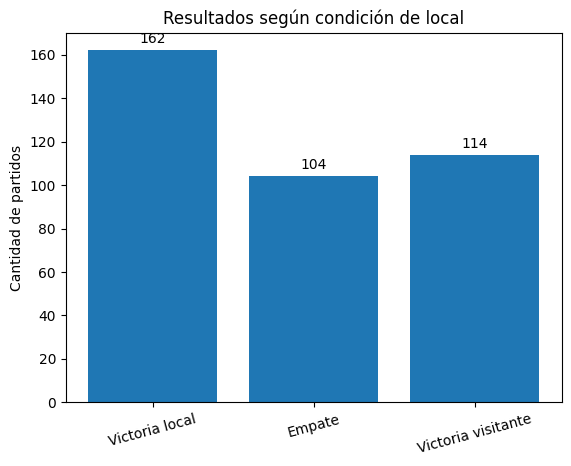

In [5]:
import matplotlib.pyplot as plt

etiquetas = ["Victoria local", "Empate", "Victoria visitante"]

valores = [
    resultados.get("H", 0),
    resultados.get("D", 0),
    resultados.get("A", 0)]

fig, ax = plt.subplots()
barras = ax.bar(etiquetas, valores)
ax.bar_label(barras, padding=3)

ax.set_title("Resultados según condición de local")
ax.set_ylabel("Cantidad de partidos")
plt.xticks(rotation=15)

plt.show()

In [6]:
# porcentaje de ventaja jugando de local
porcentaje_l = porcentajes.get("H", 0)
porcentaje_v = porcentajes.get("A", 0)
ventaja_l = porcentaje_l - porcentaje_v

print("Porcentaje de victorias locales:", round(porcentaje_l, 2), "%")
print("Porcentaje de victorias visitantes:", round(porcentaje_v, 2), "%")
print("---"*15)
print("Ventaja de jugar como local:", round(ventaja_l, 2), "prociento")
print("---"*15)

Porcentaje de victorias locales: 42.63 %
Porcentaje de victorias visitantes: 30.0 %
---------------------------------------------
Ventaja de jugar como local: 12.63 prociento
---------------------------------------------


### Conclución
Existe una ventaja estadística de jugar como local. En la temporada analizada, el 42.63% de los partidos terminó con victoria del equipo local, mientras que el 30.00% terminó con victoria del equipo visitante. La diferencia entre ambos porcentajes es de 12.63 puntos porcentuales, lo que indica una mayor frecuencia de victorias para los equipos que juegan como locales.


### ¿Qué equipos tienen el mejor rendimiento ofensivo y defensivo?

In [7]:
premier_2526.columns

Index(['Div', 'Fecha', 'Hora', 'Equipo_Local', 'Equipo_Visitante', 'FTHG',
       'FTAG', 'FTR', 'HTHG', 'HTAG',
       ...
       'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA',
       'AvgCAHH', 'AvgCAHA', 'BFECAHH', 'BFECAHA'],
      dtype='object', length=132)

In [8]:
# goles marcados y recividos como local
# agrupamos los partidos que se jugo como local
local = premier_2526.groupby("Equipo_Local").agg(
    goles_favor_local = ("FTHG", "sum"), #suma de los goles marcados por el equipo local
    goles_contra_local = ("FTAG", "sum"), # suma de los goles del visitante
    partidos_local = ("FTR", "count") # partidos jugados como local
)
# goles marcados y recividos como visitante
# agrupamos los partidos que se jugo como visitante
visitante = premier_2526.groupby("Equipo_Visitante").agg(
    goles_favor_visitante = ("FTAG", "sum"), 
    goles_contra_visitante = ("FTHG", "sum"), 
    partidos_visitante = ("FTR", "count")
)


In [9]:
# unimos las dos tablas
rendimiento = local.join(visitante, how="outer").fillna(0)

# sumamos los goles marcado como local + visitante
rendimiento["goles_favor"] = (rendimiento["goles_favor_local"] + rendimiento["goles_favor_visitante"])

# sumamos los goles en contra de ambos
rendimiento["goles_contra"] = (rendimiento["goles_contra_local"] + rendimiento["goles_contra_visitante"])

# sumamos los partigos como local y como visitante
rendimiento["partidos"] = (rendimiento["partidos_local"] + rendimiento["partidos_visitante"])

# promedio de goles marcados por partido
# nos indica el rendimiento ofencivo, mientras mayor, sera mejor el ataque
rendimiento["promedio_goles_favor"] = (rendimiento["goles_favor"]/rendimiento["partidos"])

#promedio de goles recividos por partido
# mientras mejor sea el valor, mejor devensa sera
rendimiento["promedio_goles_contra"] = (rendimiento["goles_contra"]/rendimiento["partidos"])


In [10]:
# ordenamos
#ordenamos de mayor a menor promedio de goles marcados
ofencivo = rendimiento.sort_values("promedio_goles_favor", ascending=False)

# mostramos los 10 mas ofencivos
print("Los 10 equipos con mejor ataque")
print(ofencivo[["goles_favor", "partidos", "promedio_goles_favor"]].head(10))

Los 10 equipos con mejor ataque
              goles_favor  partidos  promedio_goles_favor
Equipo_Local                                             
Man City               77        38              2.026316
Arsenal                71        38              1.868421
Man United             69        38              1.815789
Liverpool              63        38              1.657895
Bournemouth            58        38              1.526316
Chelsea                58        38              1.526316
Aston Villa            56        38              1.473684
Brentford              55        38              1.447368
Newcastle              53        38              1.394737
Brighton               52        38              1.368421


In [11]:
# los 10 mas defencivos
defensivo = rendimiento.sort_values("promedio_goles_contra", ascending=True)

print("Los 10 equipos con mejor defensa")
print(defensivo[["goles_contra", "partidos", "promedio_goles_contra"]].head(10))

Los 10 equipos con mejor defensa
                goles_contra  partidos  promedio_goles_contra
Equipo_Local                                                 
Arsenal                   27        38               0.710526
Man City                  35        38               0.921053
Brighton                  46        38               1.210526
Sunderland                48        38               1.263158
Aston Villa               49        38               1.289474
Everton                   50        38               1.315789
Man United                50        38               1.315789
Fulham                    51        38               1.342105
Nott'm Forest             51        38               1.342105
Crystal Palace            51        38               1.342105


### ¿Qué relación existe entre el resultado del primer tiempo y el resultado final?

In [13]:
etiquetas = {
    "H": "Victoria Local",
    "D": "Empate",
    "A": "Vistoria visitante"
}

# contamos cuantos partidos hay para cada conbinacion
tabla = pd.crosstab(premier_2526["HTR"], premier_2526["FTR"])
# cuenta los partidos segun la combinación de resultados del primer tiempo y del resultado final, por ejemplo, podrás identificar cuántos partidos terminaron con victoria local cuando el local ya iba ganando al descanso.

# cambiamos lo codigos por nombre
tabla = tabla.rename(index=etiquetas, columns=etiquetas)

In [14]:
# calculamos el resultado por cada resultado del primer tiempo
porcentajes_relacion = pd.crosstab(
    premier_2526["HTR"],
    premier_2526["FTR"],
    normalize="index"
)*100

# traducimos los codigos 
porcentajes_relacion = porcentajes_relacion.rename(
    index=etiquetas,
    columns=etiquetas
)

# mostramos los resultados
porcentajes_relacion.round(2)

FTR,Vistoria visitante,Empate,Victoria Local
HTR,,,
Vistoria visitante,70.33,17.58,12.09
Empate,26.39,43.75,29.86
Victoria Local,8.28,17.24,74.48


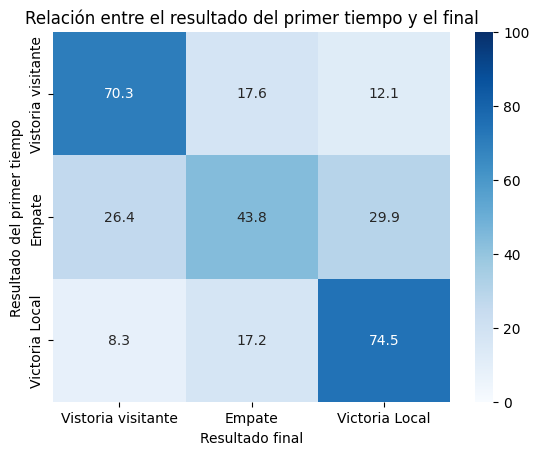

In [15]:
# creamos el grafico
import seaborn as sns

plt.Figure(figsize=(9, 12))

sns.heatmap(
    porcentajes_relacion,
    annot= True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100)

plt.title("Relación entre el resultado del primer tiempo y el final")
plt.xlabel("Resultado final")
plt.ylabel("Resultado del primer tiempo")

plt.show()

##### Existe una relación entre el resultado del primer tiempo y el resultado final de los partidos de la Premier League. Los equipos que llegan al descanso con ventaja tienen mayores posibilidades de terminar ganando, mientras que los partidos empatados al descanso pueden terminar en victoria local, empate o victoria visitante. Esto demuestra que el resultado del primer tiempo es un indicador útil para analizar el desenlace del encuentro, aunque no garantiza el resultado final.

### ¿Qué equipos generan más partidos con muchos goles?

In [17]:
# sumamos los goles de de cada equipo en sus partidos
premier_2526["Goles_Totales"] = (premier_2526["FTHG"] + premier_2526["FTAG"])

# vemos los partidos con mas goles
premier_2526["Muchos_Goles"] = (premier_2526["Goles_Totales"] >= 4)

In [26]:
# vemos algunos resultados
premier_2526[["Equipo_Local",
            "Equipo_Visitante",
            "Goles_Totales",
            "Muchos_Goles"]].head()

,Equipo_Local,Equipo_Visitante,Goles_Totales,Muchos_Goles
0,Liverpool,Bournemouth,6,True
1,Aston Villa,Newcastle,0,False
2,Brighton,Fulham,2,False
3,Sunderland,West Ham,3,False
4,Tottenham,Burnley,3,False


In [ ]:
# partidos con mas goles (=> 4)
local = premier_2526.groupby("Equipo_Local")["Muchos_Goles"].sum()
visitante = premier_2526.groupby("Equipo_Visitante")["Muchos_Goles"].sum()

In [32]:
# sumamos los goles de ambos
partidos_goleadores = (local.add(visitante, fill_value=0).sort_values(ascending=False))

#mostramos los 10 partido con mas goles
partidos_goleadores.head(10)

Equipo_Local
Bournemouth    16
Burnley        15
Leeds          14
Brentford      14
Man United     14
Newcastle      13
Chelsea        12
Aston Villa    11
Liverpool      11
West Ham       11
Name: Muchos_Goles, dtype: int64

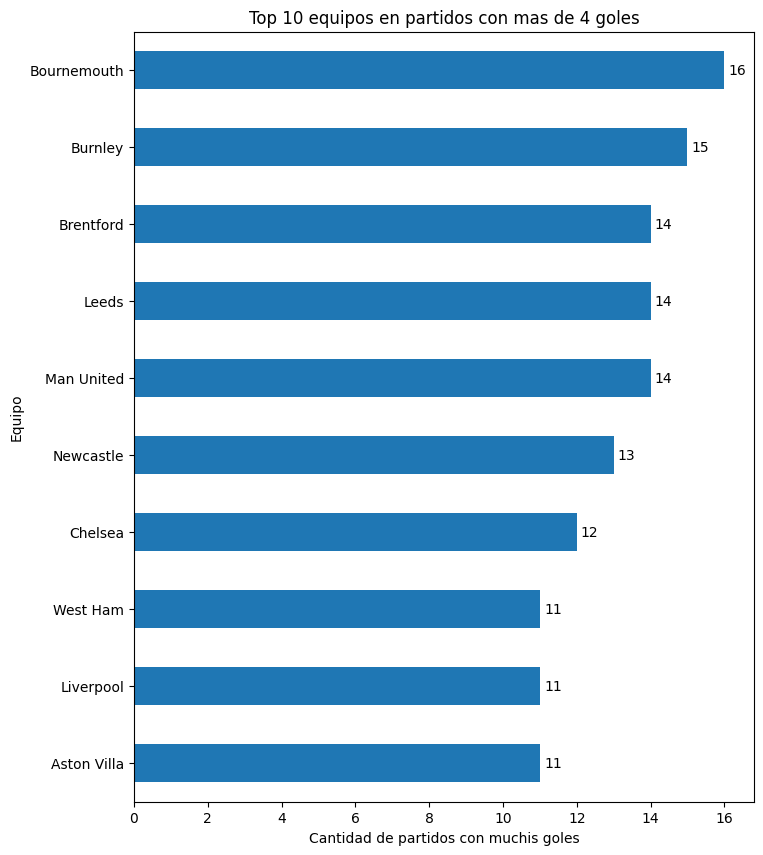

In [34]:
# seleccionamos los partidos con mas goles
top_10 = partidos_goleadores.head(10).sort_values()

# creamos los graficos
ax = top_10.plot(kind="barh", figsize=(8, 10))

# agregamos los valores
ax.bar_label(ax.containers[0], padding=3)

plt.title("Top 10 equipos en partidos con mas de 4 goles")
plt.xlabel("Cantidad de partidos con muchis goles")
plt.ylabel("Equipo")
plt.tight_layout
plt.show()

#### Considerando como partidos con muchos goles aquellos en los que se anotan cuatro o más goles entre ambos equipos, Bournemouth destaca con 16 encuentros, seguido de Burnley con 15. Leeds, Brentford y Manchester United registran 14 partidos cada uno. Esto indica que los encuentros en los que participan estos equipos suelen presentar una mayor cantidad de goles, independientemente de cuál de los dos equipos los anote.